# A/B Test: Should a Mobile Game Move Its First Paywall Gate?

**Business problem:** product teams change apps constantly and need to know whether a change helped or hurt before rolling it out to everyone. Here, the makers of the puzzle game *Cookie Cats* tested moving the first "gate" (a point where players must wait or pay to continue) from **level 30 to level 40**. The worry: does a later gate reduce how many players come back?

**Data:** 90,189 players who installed the game during the test, randomly assigned to `gate_30` (control) or `gate_40` (treatment). For each player: game rounds played in the first 14 days, and whether they came back **1 day** and **7 days** after installing. Source: the Cookie Cats test data published by DataCamp from Tactile Entertainment.

**Tools:** Python (pandas, NumPy, SciPy, matplotlib).

**Steps:** data checks → sample ratio check → retention by group with confidence intervals → significance test → bootstrap → decision.

In [1]:
import json, os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold", "axes.titlesize": 12,
})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
os.makedirs("images", exist_ok=True); os.makedirs("results", exist_ok=True); os.makedirs("data", exist_ok=True)

from scipy import stats

DATA_PATH = "data/cookie_cats.csv"
if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/ryanschaub/Mobile-Games-A-B-Testing-with-Cookie-Cats/master/cookie_cats.csv", DATA_PATH)
ab = pd.read_csv(DATA_PATH)
print(ab.shape)
ab.head()

(90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 1. Data checks

In [2]:
checks = pd.Series({
    "players": len(ab),
    "duplicate user IDs": int(ab["userid"].duplicated().sum()),
    "missing values": int(ab.isna().sum().sum()),
    "players with 0 rounds played": int((ab["sum_gamerounds"] == 0).sum()),
    "median rounds": float(ab["sum_gamerounds"].median()),
    "max rounds (one player)": int(ab["sum_gamerounds"].max()),
    "second highest rounds": int(ab["sum_gamerounds"].nlargest(2).iloc[-1]),
})
checks

players                        90,189.000
duplicate user IDs                  0.000
missing values                      0.000
players with 0 rounds played    3,994.000
median rounds                      16.000
max rounds (one player)        49,854.000
second highest rounds           2,961.000
dtype: float64

One player logged 49,854 rounds in 14 days, about 17 times the next highest (2,961) and roughly 150 rounds an hour without sleep. That looks like a logging error or a bot, so they are excluded from the rounds comparison. They are kept in the retention analysis because a yes/no retention flag is not distorted by one extreme value.

## 2. Sample ratio check

If assignment was a fair 50/50 split, the two groups should be about the same size. A chi-square test checks whether the difference is bigger than chance would produce. A failed check is called a **sample ratio mismatch** and is a warning that something in the assignment or logging may be broken.

In [3]:
counts = ab["version"].value_counts().reindex(["gate_30", "gate_40"])
chi2, srm_p = stats.chisquare(counts.values)
srm = {"gate_30": int(counts["gate_30"]), "gate_40": int(counts["gate_40"]),
       "gate_30_share_pct": round(100 * counts["gate_30"] / counts.sum(), 2), "chi2": round(chi2, 2), "p_value": round(srm_p, 4)}
srm

{'gate_30': 44700,
 'gate_40': 45489,
 'gate_30_share_pct': np.float64(49.56),
 'chi2': np.float64(6.9),
 'p_value': np.float64(0.0086)}

## 3. Retention by group

In [4]:
def prop_ci(successes, n, z=1.96):
    p = successes / n
    se = np.sqrt(p * (1 - p) / n)
    return p, p - z * se, p + z * se

rows = []
for metric in ["retention_1", "retention_7"]:
    for v in ["gate_30", "gate_40"]:
        g = ab[ab["version"] == v][metric]
        p, lo, hi = prop_ci(g.sum(), len(g))
        rows.append({"metric": metric, "version": v, "players": len(g), "retained": int(g.sum()),
                     "rate_pct": round(100 * p, 2), "ci_low_pct": round(100 * lo, 2), "ci_high_pct": round(100 * hi, 2)})
retention = pd.DataFrame(rows)
retention

,metric,version,players,retained,rate_pct,ci_low_pct,ci_high_pct
0,retention_1,gate_30,44700,20034,44.820,44.360,45.280
1,retention_1,gate_40,45489,20119,44.230,43.770,44.680
2,retention_7,gate_30,44700,8502,19.020,18.660,19.380
3,retention_7,gate_40,45489,8279,18.200,17.850,18.550


In [5]:
def two_prop_z(metric):
    a = ab[ab["version"] == "gate_30"][metric]; b = ab[ab["version"] == "gate_40"][metric]
    p1, p2, n1, n2 = a.mean(), b.mean(), len(a), len(b)
    pooled = (a.sum() + b.sum()) / (n1 + n2)
    se = np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    z = (p2 - p1) / se
    p = 2 * (1 - stats.norm.cdf(abs(z)))
    se_diff = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    diff = p2 - p1
    return {"diff_pp": round(100 * diff, 2), "ci_low_pp": round(100 * (diff - 1.96 * se_diff), 2),
            "ci_high_pp": round(100 * (diff + 1.96 * se_diff), 2), "relative_change_pct": round(100 * diff / p1, 1),
            "z": round(z, 2), "p_value": round(p, 4)}

tests = {m: two_prop_z(m) for m in ["retention_1", "retention_7"]}
pd.DataFrame(tests).T

,diff_pp,ci_low_pp,ci_high_pp,relative_change_pct,z,p_value
retention_1,-0.590,-1.240,0.060,-1.300,-1.780,0.074
retention_7,-0.820,-1.330,-0.310,-4.300,-3.160,0.002


## 4. Bootstrap

Simulating the experiment 5,000 times (a parametric bootstrap that redraws each group's number of returning players from its observed rate) gives the full distribution of the difference, and a direct answer to the question a product manager actually asks: *how likely is it that gate 30 is better?*

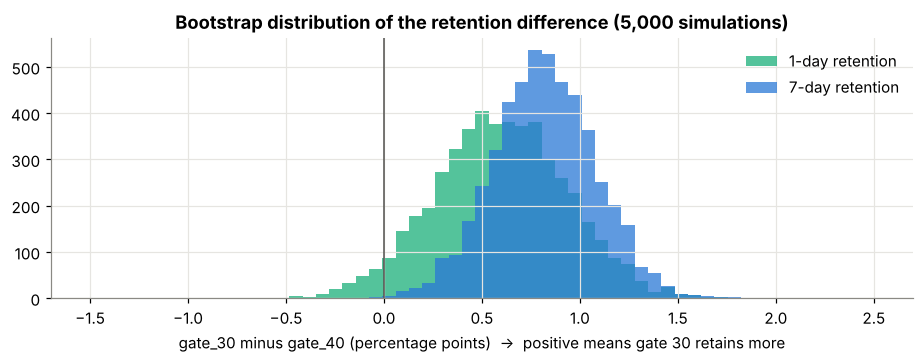

{'retention_1': np.float64(96.2), 'retention_7': np.float64(99.9)}

In [6]:
rng = np.random.default_rng(42)
B = 5000
boot = {}
for metric in ["retention_1", "retention_7"]:
    a = ab.loc[ab["version"] == "gate_30", metric].to_numpy(dtype=float)
    b = ab.loc[ab["version"] == "gate_40", metric].to_numpy(dtype=float)
    da = rng.binomial(len(a), a.mean(), B) / len(a)
    db = rng.binomial(len(b), b.mean(), B) / len(b)
    boot[metric] = 100 * (da - db)  # positive = gate_30 better, in percentage points

prob_30_better = {m: round(100 * (v > 0).mean(), 1) for m, v in boot.items()}

fig, ax = plt.subplots(figsize=(8.5, 3.4))
bins = np.linspace(-1.5, 2.5, 60)
ax.hist(boot["retention_1"], bins=bins, color=AQUA, alpha=0.75, label="1-day retention")
ax.hist(boot["retention_7"], bins=bins, color=BLUE, alpha=0.75, label="7-day retention")
ax.axvline(0, color="#52514e", lw=1)
ax.set_xlabel("gate_30 minus gate_40 (percentage points)  →  positive means gate 30 retains more")
ax.set_title("Bootstrap distribution of the retention difference (5,000 simulations)"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("images/bootstrap_difference.png"); plt.show()
prob_30_better

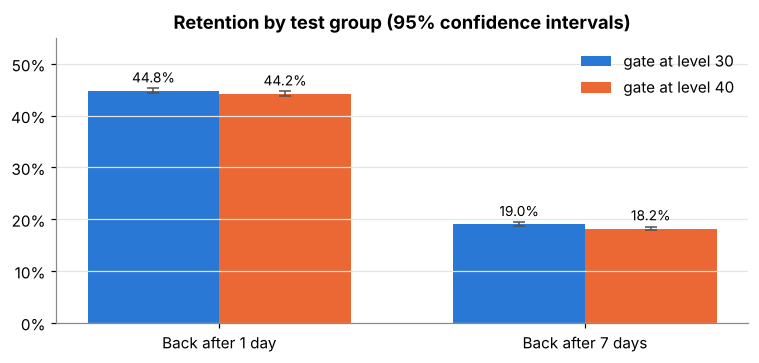

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(2); w = 0.36
for i, (v, col) in enumerate([("gate_30", BLUE), ("gate_40", ORANGE)]):
    r = retention[retention["version"] == v].set_index("metric")
    vals = r["rate_pct"].values; err = [vals - r["ci_low_pct"].values, r["ci_high_pct"].values - vals]
    ax.bar(x + (i - 0.5) * w, vals, width=w, color=col, label=v.replace("_", " at level "), yerr=err, capsize=4, error_kw={"lw": 1, "ecolor": "#52514e"})
    for xi, val in zip(x + (i - 0.5) * w, vals):
        ax.text(xi, val + 1.6, f"{val:.1f}%", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(["Back after 1 day", "Back after 7 days"]); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Retention by test group (95% confidence intervals)"); ax.legend(frameon=False); ax.grid(axis="x", visible=False); ax.set_ylim(0, 55)
fig.tight_layout(); fig.savefig("images/retention_by_group.png"); plt.show()

In [8]:
clean = ab[ab["sum_gamerounds"] < 10000]
rounds = clean.groupby("version")["sum_gamerounds"].agg(["median", "mean"]).round(1)
mw = stats.mannwhitneyu(clean.loc[clean["version"] == "gate_30", "sum_gamerounds"], clean.loc[clean["version"] == "gate_40", "sum_gamerounds"])
print(rounds); print(f"Mann-Whitney U p-value: {mw.pvalue:.3f}")

         median   mean
version               
gate_30  17.000 51.300
gate_40  16.000 51.300
Mann-Whitney U p-value: 0.051


## Findings

| | Gate at level 30 | Gate at level 40 | Difference | p-value |
|---|---|---|---|---|
| Back after 1 day | 44.82% | 44.23% | −0.59 pp (95% CI −1.24 to +0.06) | 0.074 |
| Back after 7 days | 19.02% | 18.20% | **−0.82 pp** (95% CI −1.33 to −0.31) | **0.002** |

1. **Moving the gate to level 40 lowered 7-day retention.** The drop is 0.82 percentage points, 4.3% in relative terms, and the bootstrap puts the chance that level 30 retains better at 99.9%. At scale, that is about 820 fewer players still playing a week later for every 100,000 installs.
2. **The 1-day effect points the same way but is not conclusive** (p = 0.074; the confidence interval includes zero).
3. **Engagement barely moved.** Median rounds played were 17 against 16, a difference that is not statistically significant (p = 0.051).
4. **The split was not a clean 50/50.** gate_30 got 49.56% of players. A chi-square test gives p = 0.009, a sample ratio mismatch. Before acting, I would check the assignment and logging pipeline. The retention result points the same way on both measures, so it is unlikely to be explained by the imbalance alone, but it should be investigated.
5. **Data quality:** 3,994 players (4.4%) installed but never played a round, and one account logged 49,854 rounds, which looks like a bot or logging error.

**Recommendation:** keep the gate at level 30, and fix or explain the sample ratio mismatch before the next test.

**Why might a later gate hurt?** One hypothesis is that an enforced break keeps the game feeling fresh, so players who hit it earlier come back. This test cannot prove that; it would need a follow-up.

In [9]:
summary = {
    "checks": {k: float(v) for k, v in checks.items()},
    "srm": srm,
    "retention": retention.to_dict(orient="records"),
    "tests": tests,
    "prob_30_better_pct": prob_30_better,
    "rounds": {v: {"median": float(r["median"]), "mean": float(r["mean"])} for v, r in rounds.iterrows()},
    "rounds_mw_p": round(float(mw.pvalue), 3),
    "boot_hist": {m: np.histogram(v, bins=np.linspace(-1.5, 2.5, 41))[0].tolist() for m, v in boot.items()},
    "boot_edges": np.linspace(-1.5, 2.5, 41).round(2).tolist(),
}
json.dump(summary, open("results/summary.json", "w"), indent=1)
print("saved results/summary.json")

saved results/summary.json
